In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import sklearn

SEED = 42
N_FOLDS = 3

ROOT = Path("/kaggle/input")
OUT = Path("/kaggle/working/S7")
OUT.mkdir(parents=True, exist_ok=True)

print("=== S7: GROUP-VECTOR CV ===")
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\n=== DATASET ===")

csv_candidates = list(ROOT.rglob(
    "diabetes_binary_health_indicators_BRFSS2015.csv"
))

for p in csv_candidates:
    print(p)

print("\n=== TRAIN INDEX ===")

idx_candidates = list(ROOT.rglob("idx_train.npy"))

for p in idx_candidates:
    print(p)

print("\n=== PIPELINE B ===")

for p in ROOT.rglob("b2_b3_pipeline.py"):
    print(p)

print("\nOutput:", OUT)


=== S7: GROUP-VECTOR CV ===
Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1

=== DATASET ===
/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv

=== TRAIN INDEX ===
/kaggle/input/datasets/dinhgiaphong/b-v15-code/idx_train.npy

=== PIPELINE B ===
/kaggle/input/datasets/dinhgiaphong/b-v15-code/b2_b3_pipeline.py

Output: /kaggle/working/S7


In [2]:

# SHA-256 tham chiếu từ notebook QA của D
EXPECTED_DATA_HASH = (
    "19f367e3e3350768f0c144c5d73ee5b355"
    "f67a57eaaa86ca7bd8aec594d8b1d0"
)

# SHA-256 xác minh trực tiếp từ B v15
EXPECTED_TRAIN_HASH = (
    "a38179b95ad36c91e9f854fb04f5b5363"
    "ee0a1a914d6aecddad7927d0e06980c"
)

def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


# Chọn đúng dữ liệu theo mã băm
valid_csv = [
    p for p in csv_candidates
    if sha256_file(p) == EXPECTED_DATA_HASH
]

assert len(valid_csv) == 1, (
    "Không xác định được duy nhất CSV hợp lệ."
)

DATA_PATH = valid_csv[0]


# Chọn đúng index train B v15
valid_idx = [
    p for p in idx_candidates
    if sha256_file(p) == EXPECTED_TRAIN_HASH
]

assert len(valid_idx) == 1, (
    "Không xác định được duy nhất index B v15."
)

IDX_TRAIN_PATH = valid_idx[0]

idx_train = np.load(
    IDX_TRAIN_PATH,
    allow_pickle=False
)

assert idx_train.ndim == 1
assert np.issubdtype(idx_train.dtype, np.integer)
assert len(idx_train) == 177576
assert len(np.unique(idx_train)) == 177576
assert idx_train.min() >= 0
assert idx_train.max() < 253680


# Đọc CSV và chỉ giữ các bản ghi train
df = pd.read_csv(DATA_PATH)

assert df.shape == (253680, 22)

train_df = (
    df.iloc[idx_train]
    .copy()
    .reset_index(drop=True)
)

# Không giữ toàn bộ dữ liệu trong bộ nhớ
del df

TARGET = "Diabetes_binary"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET].astype(int)

assert X_train.shape == (177576, 21)
assert set(y_train.unique()) == {0, 1}
assert X_train.isna().sum().sum() == 0

print("=== DATA AUDIT ===")
print("Dataset:", DATA_PATH)
print("Data SHA-256: PASS")
print("Train index:", IDX_TRAIN_PATH)
print("Index SHA-256: PASS")

print("\nX_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nClass distribution:")
print(y_train.value_counts().sort_index())

print("\nPositive rate:")
print(round(y_train.mean(), 6))

print("\nFeature names:")
print(X_train.columns.tolist())

print("\nS7.2: PASS")


=== DATA AUDIT ===
Dataset: /kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv
Data SHA-256: PASS
Train index: /kaggle/input/datasets/dinhgiaphong/b-v15-code/idx_train.npy
Index SHA-256: PASS

X_train: (177576, 21)
y_train: (177576,)

Class distribution:
Diabetes_binary
0    152834
1     24742
Name: count, dtype: int64

Positive rate:
0.139332

Feature names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

S7.2: PASS


In [3]:

# ==========================================
# S7.3 - GROUP VECTOR CONSTRUCTION
# ==========================================

# Tạo mã băm cho từng vector đặc trưng
group_hashes = pd.util.hash_pandas_object(
    X_train,
    index=False
)

# Chuyển hash thành Group ID dạng số nguyên
groups, unique_hashes = pd.factorize(
    group_hashes,
    sort=False
)

groups = groups.astype(np.int64)

# Kiểm tra kích thước
assert len(groups) == len(X_train)
assert groups.min() == 0

# Đếm số vector duy nhất trực tiếp
n_unique_vectors = len(
    X_train.drop_duplicates()
)

n_groups = len(np.unique(groups))

# Kiểm tra số nhóm khớp số vector duy nhất
assert n_groups == n_unique_vectors

# Thống kê kích thước từng nhóm
group_sizes = pd.Series(groups).value_counts()

n_duplicate_groups = int(
    (group_sizes > 1).sum()
)

n_rows_in_duplicate_groups = int(
    group_sizes[group_sizes > 1].sum()
)

n_extra_rows = len(X_train) - n_groups

# Kiểm tra nhóm chứa nhãn khác nhau
group_audit = pd.DataFrame({
    "group_id": groups,
    "target": y_train.to_numpy()
})

labels_per_group = (
    group_audit
    .groupby("group_id")["target"]
    .nunique()
)

n_conflicting_groups = int(
    (labels_per_group > 1).sum()
)

print("=== GROUP VECTOR AUDIT ===")
print("Total train rows:", len(X_train))
print("Unique vectors:", n_unique_vectors)
print("Total groups:", n_groups)

print("\nDuplicate groups:", n_duplicate_groups)
print("Rows in duplicate groups:", 
      n_rows_in_duplicate_groups)
print("Extra duplicate rows:", n_extra_rows)

print("Extra duplicate rate:",
      round(n_extra_rows / len(X_train), 6))

print("Largest group:", group_sizes.max())
print("Conflicting-label groups:",
      n_conflicting_groups)

print("\nFirst 10 Group IDs:")
print(groups[:10])

# Lưu Group ID
np.save(
    OUT / "group_ids_train.npy",
    groups
)

print("\nSaved:", OUT / "group_ids_train.npy")
print("S7.3: PASS")


=== GROUP VECTOR AUDIT ===
Total train rows: 177576
Unique vectors: 162300
Total groups: 162300

Duplicate groups: 7724
Rows in duplicate groups: 23000
Extra duplicate rows: 15276
Extra duplicate rate: 0.086025
Largest group: 42
Conflicting-label groups: 885

First 10 Group IDs:
[0 1 2 3 4 5 6 7 8 9]

Saved: /kaggle/working/S7/group_ids_train.npy
S7.3: PASS


In [4]:

# ==========================================
# S7.4 - CV SPLIT AUDIT
# ==========================================

from sklearn.model_selection import (
    StratifiedKFold,
    GroupKFold
)

# 1. Khởi tạo hai phương pháp CV
skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

gkf = GroupKFold(
    n_splits=N_FOLDS
)

# 2. Tạo các fold một lần duy nhất
stratified_splits = list(
    skf.split(X_train, y_train)
)

group_splits = list(
    gkf.split(X_train, y_train, groups=groups)
)

cv_splits = {
    "StratifiedKFold": stratified_splits,
    "GroupKFold": group_splits
}

# 3. Kiểm tra từng fold
audit_rows = []

for method, splits in cv_splits.items():

    eval_indices_all = []

    for fold, (tr_idx, ev_idx) in enumerate(
        splits, start=1
    ):

        # Kiểm tra index
        index_overlap = np.intersect1d(
            tr_idx, ev_idx
        )

        assert len(index_overlap) == 0

        assert (
            len(tr_idx) + len(ev_idx)
            == len(X_train)
        )

        # Kiểm tra cả hai lớp
        assert y_train.iloc[tr_idx].nunique() == 2
        assert y_train.iloc[ev_idx].nunique() == 2

        # Kiểm tra Group ID
        tr_groups = np.unique(groups[tr_idx])
        ev_groups = np.unique(groups[ev_idx])

        shared_groups = np.intersect1d(
            tr_groups, ev_groups
        )

        n_shared_groups = len(shared_groups)

        # Số bản ghi đánh giá có vector
        # từng xuất hiện trong fold train
        shared_eval_rows = int(
            np.isin(
                groups[ev_idx],
                shared_groups
            ).sum()
        )

        shared_eval_rate = (
            shared_eval_rows / len(ev_idx)
        )

        # GroupKFold không được có nhóm chung
        if method == "GroupKFold":
            assert n_shared_groups == 0
            assert shared_eval_rows == 0

        audit_rows.append({
            "method": method,
            "fold": fold,

            "n_train": len(tr_idx),
            "n_eval": len(ev_idx),

            "train_positive_rate":
                y_train.iloc[tr_idx].mean(),

            "eval_positive_rate":
                y_train.iloc[ev_idx].mean(),

            "n_train_groups": len(tr_groups),
            "n_eval_groups": len(ev_groups),

            "index_overlap": len(index_overlap),

            "shared_groups": n_shared_groups,

            "shared_eval_rows": shared_eval_rows,

            "shared_eval_rate": shared_eval_rate
        })

        eval_indices_all.append(ev_idx)

    # Mỗi bản ghi phải được đánh giá đúng một lần
    all_eval = np.concatenate(eval_indices_all)

    assert np.array_equal(
        np.sort(all_eval),
        np.arange(len(X_train))
    )

# 4. Tổng hợp bảng QA
fold_audit = pd.DataFrame(audit_rows)

print("=== CV SPLIT AUDIT ===")

print(
    fold_audit.round(6).to_string(index=False)
)

# 5. Thống kê theo phương pháp
print("\n=== SUMMARY BY METHOD ===")

summary = (
    fold_audit.groupby("method")[
        [
            "index_overlap",
            "shared_groups",
            "shared_eval_rows",
            "shared_eval_rate",
            "eval_positive_rate"
        ]
    ]
    .mean()
)

print(summary.round(6).to_string())

# 6. Lưu kết quả QA
fold_audit.to_csv(
    OUT / "s7_fold_audit.csv",
    index=False
)

# 7. Lưu index của từng fold
fold_arrays = {}

for method, splits in cv_splits.items():

    for fold, (tr_idx, ev_idx) in enumerate(
        splits, start=1
    ):

        prefix = f"{method}_fold{fold}"

        fold_arrays[f"{prefix}_train"] = tr_idx
        fold_arrays[f"{prefix}_eval"] = ev_idx

np.savez_compressed(
    OUT / "s7_cv_splits.npz",
    **fold_arrays
)

print("\nSaved:")
print(OUT / "s7_fold_audit.csv")
print(OUT / "s7_cv_splits.npz")

print("\nS7.4: PASS")


=== CV SPLIT AUDIT ===
         method  fold  n_train  n_eval  train_positive_rate  eval_positive_rate  n_train_groups  n_eval_groups  index_overlap  shared_groups  shared_eval_rows  shared_eval_rate
StratifiedKFold     1   118384   59192             0.139335            0.139326          110068          56509              0           4277              6315          0.106687
StratifiedKFold     2   118384   59192             0.139335            0.139326          110224          56430              0           4354              6419          0.108444
StratifiedKFold     3   118384   59192             0.139326            0.139343          110168          56379              0           4247              6344          0.107177
     GroupKFold     1   118384   59192             0.139766            0.138465          108200          54100              0              0                 0          0.000000
     GroupKFold     2   118384   59192             0.139394            0.139208          108

In [5]:

# ==========================================
# S7.5 - LOGISTIC REGRESSION SENSITIVITY
# ==========================================

import time

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)


# 1. Xây dựng hàm CV dùng chung
def run_sensitivity_cv(model_name, estimator):

    rows = []
    oof_scores = {}

    for method, splits in cv_splits.items():

        print(f"\n=== {model_name} | {method} ===")

        # Lưu điểm dự đoán ngoài fold
        oof = np.full(
            len(y_train),
            np.nan,
            dtype=np.float64
        )

        for fold, (tr_idx, ev_idx) in enumerate(
            splits, start=1
        ):

            start = time.perf_counter()

            # Tạo mô hình mới cho mỗi fold
            model = clone(estimator)

            X_tr = X_train.iloc[tr_idx]
            y_tr = y_train.iloc[tr_idx]

            X_ev = X_train.iloc[ev_idx]
            y_ev = y_train.iloc[ev_idx]

            # Huấn luyện chỉ trên fold train
            model.fit(X_tr, y_tr)

            # Điểm dự đoán lớp dương
            pos_col = np.where(
                model.classes_ == 1
            )[0][0]

            scores = model.predict_proba(
                X_ev
            )[:, pos_col]

            # Kiểm tra đầu ra
            assert len(scores) == len(ev_idx)
            assert np.isfinite(scores).all()
            assert ((scores >= 0) &
                    (scores <= 1)).all()

            assert np.isnan(oof[ev_idx]).all()

            # Lưu dự đoán ngoài fold
            oof[ev_idx] = scores

            # Tính metrics
            ap = average_precision_score(
                y_ev, scores
            )

            auc = roc_auc_score(
                y_ev, scores
            )

            elapsed = time.perf_counter() - start

            rows.append({
                "model": model_name,
                "method": method,
                "fold": fold,
                "n_train": len(tr_idx),
                "n_eval": len(ev_idx),
                "eval_positive_rate":
                    float(y_ev.mean()),
                "AP": float(ap),
                "ROC_AUC": float(auc),
                "seconds": elapsed
            })

            print(
                f"Fold {fold}: "
                f"AP={ap:.6f} | "
                f"AUC={auc:.6f} | "
                f"Time={elapsed:.2f}s",
                flush=True
            )

        # Mỗi bản ghi train phải có một
        # điểm dự đoán ngoài fold
        assert np.isfinite(oof).all()

        oof_scores[method] = oof

    return pd.DataFrame(rows), oof_scores


# 2. Khởi tạo Logistic Regression
lr_model = Pipeline([
    ("scaler", StandardScaler()),

    ("clf", LogisticRegression(
        C=0.001,
        max_iter=5000,
        solver="lbfgs",
        penalty="l2",
        class_weight=None,
        random_state=SEED
    ))
])


# 3. Chạy hai phương pháp CV
lr_fold_results, lr_oof = run_sensitivity_cv(
    "B1_logistic",
    lr_model
)


# 4. Tổng hợp kết quả
lr_summary = (
    lr_fold_results
    .groupby(["model", "method"])
    .agg(
        cv_AP=("AP", "mean"),

        cv_AP_std=(
            "AP",
            lambda x: np.std(x, ddof=0)
        ),

        cv_AUC=("ROC_AUC", "mean"),

        cv_AUC_std=(
            "ROC_AUC",
            lambda x: np.std(x, ddof=0)
        ),

        total_seconds=("seconds", "sum")
    )
    .reset_index()
)

print("\n=== LR CV SUMMARY ===")
print(
    lr_summary.round(6).to_string(index=False)
)


# 5. Tính chênh lệch AP
lr_ap_stratified = lr_summary.loc[
    lr_summary["method"] == "StratifiedKFold",
    "cv_AP"
].iloc[0]

lr_ap_group = lr_summary.loc[
    lr_summary["method"] == "GroupKFold",
    "cv_AP"
].iloc[0]

lr_delta_ap = lr_ap_group - lr_ap_stratified

print("\n=== LR AP DIFFERENCE ===")
print(f"Stratified AP: {lr_ap_stratified:.6f}")
print(f"Group AP:      {lr_ap_group:.6f}")
print(f"Delta AP:      {lr_delta_ap:+.6f}")

print("\nHistorical CV-AP: 0.4071")
print(
    "Difference from historical:",
    round(lr_ap_stratified - 0.4071, 6)
)


# 6. Lưu minh chứng
lr_fold_results.to_csv(
    OUT / "s7_lr_fold_results.csv",
    index=False
)

lr_summary.to_csv(
    OUT / "s7_lr_summary.csv",
    index=False
)

np.savez_compressed(
    OUT / "s7_lr_oof_predictions.npz",

    row_indices=idx_train,
    y_true=y_train.to_numpy(),

    scores_stratified=lr_oof[
        "StratifiedKFold"
    ],

    scores_group=lr_oof[
        "GroupKFold"
    ]
)

print("\nSaved:")
print(OUT / "s7_lr_fold_results.csv")
print(OUT / "s7_lr_summary.csv")
print(OUT / "s7_lr_oof_predictions.npz")

print("\nS7.5: PASS")



=== B1_logistic | StratifiedKFold ===
Fold 1: AP=0.410416 | AUC=0.824698 | Time=0.44s
Fold 2: AP=0.409120 | AUC=0.822806 | Time=0.36s
Fold 3: AP=0.401669 | AUC=0.820061 | Time=0.30s

=== B1_logistic | GroupKFold ===
Fold 1: AP=0.410716 | AUC=0.824845 | Time=0.31s
Fold 2: AP=0.403330 | AUC=0.821432 | Time=0.34s
Fold 3: AP=0.407223 | AUC=0.821081 | Time=0.41s

=== LR CV SUMMARY ===
      model          method    cv_AP  cv_AP_std   cv_AUC  cv_AUC_std  total_seconds
B1_logistic      GroupKFold 0.407090   0.003017 0.822453    0.001698       1.062392
B1_logistic StratifiedKFold 0.407068   0.003854 0.822522    0.001904       1.111087

=== LR AP DIFFERENCE ===
Stratified AP: 0.407068
Group AP:      0.407090
Delta AP:      +0.000022

Historical CV-AP: 0.4071
Difference from historical: -3.2e-05

Saved:
/kaggle/working/S7/s7_lr_fold_results.csv
/kaggle/working/S7/s7_lr_summary.csv
/kaggle/working/S7/s7_lr_oof_predictions.npz

S7.5: PASS


In [6]:

# ==========================================
# S7.6 - RANDOM FOREST SENSITIVITY
# ==========================================

from sklearn.ensemble import RandomForestClassifier


# 1. Khởi tạo Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,

    criterion="gini",
    max_features="sqrt",

    min_samples_split=2,
    min_samples_leaf=1,

    bootstrap=True,
    class_weight=None,

    random_state=SEED,
    n_jobs=2
)


# 2. Chạy hai phương pháp CV
rf_fold_results, rf_oof = run_sensitivity_cv(
    "B2_random_forest",
    rf_model
)


# 3. Tổng hợp kết quả
rf_summary = (
    rf_fold_results
    .groupby(["model", "method"])
    .agg(
        cv_AP=("AP", "mean"),

        cv_AP_std=(
            "AP",
            lambda x: np.std(x, ddof=0)
        ),

        cv_AUC=("ROC_AUC", "mean"),

        cv_AUC_std=(
            "ROC_AUC",
            lambda x: np.std(x, ddof=0)
        ),

        total_seconds=("seconds", "sum")
    )
    .reset_index()
)

print("\n=== RF CV SUMMARY ===")

print(
    rf_summary.round(6).to_string(index=False)
)


# 4. Tính chênh lệch AP
rf_ap_stratified = rf_summary.loc[
    rf_summary["method"] == "StratifiedKFold",
    "cv_AP"
].iloc[0]

rf_ap_group = rf_summary.loc[
    rf_summary["method"] == "GroupKFold",
    "cv_AP"
].iloc[0]

rf_delta_ap = rf_ap_group - rf_ap_stratified

print("\n=== RF AP DIFFERENCE ===")

print(f"Stratified AP: {rf_ap_stratified:.6f}")
print(f"Group AP:      {rf_ap_group:.6f}")
print(f"Delta AP:      {rf_delta_ap:+.6f}")

print("\nHistorical CV-AP: 0.4304")

print(
    "Difference from historical:",
    round(rf_ap_stratified - 0.4304, 6)
)


# 5. Lưu minh chứng
rf_fold_results.to_csv(
    OUT / "s7_rf_fold_results.csv",
    index=False
)

rf_summary.to_csv(
    OUT / "s7_rf_summary.csv",
    index=False
)

np.savez_compressed(
    OUT / "s7_rf_oof_predictions.npz",

    row_indices=idx_train,
    y_true=y_train.to_numpy(),

    scores_stratified=rf_oof[
        "StratifiedKFold"
    ],

    scores_group=rf_oof[
        "GroupKFold"
    ]
)

print("\nSaved:")
print(OUT / "s7_rf_fold_results.csv")
print(OUT / "s7_rf_summary.csv")
print(OUT / "s7_rf_oof_predictions.npz")

print("\nS7.6: PASS")



=== B2_random_forest | StratifiedKFold ===
Fold 1: AP=0.436371 | AUC=0.828921 | Time=13.60s
Fold 2: AP=0.429676 | AUC=0.826255 | Time=13.13s
Fold 3: AP=0.425034 | AUC=0.825506 | Time=14.18s

=== B2_random_forest | GroupKFold ===
Fold 1: AP=0.435110 | AUC=0.828906 | Time=14.25s
Fold 2: AP=0.426847 | AUC=0.826179 | Time=14.21s
Fold 3: AP=0.430104 | AUC=0.825381 | Time=14.17s

=== RF CV SUMMARY ===
           model          method    cv_AP  cv_AP_std   cv_AUC  cv_AUC_std  total_seconds
B2_random_forest      GroupKFold 0.430687   0.003399 0.826822    0.001509      42.624706
B2_random_forest StratifiedKFold 0.430360   0.004653 0.826894    0.001465      40.905432

=== RF AP DIFFERENCE ===
Stratified AP: 0.430360
Group AP:      0.430687
Delta AP:      +0.000327

Historical CV-AP: 0.4304
Difference from historical: -4e-05

Saved:
/kaggle/working/S7/s7_rf_fold_results.csv
/kaggle/working/S7/s7_rf_summary.csv
/kaggle/working/S7/s7_rf_oof_predictions.npz

S7.6: PASS


=== S7 FULL CV SUMMARY ===
           model          method    cv_AP  cv_AP_std   cv_AUC  cv_AUC_std  total_seconds
     B1_logistic      GroupKFold 0.407090   0.003017 0.822453    0.001698       1.062392
     B1_logistic StratifiedKFold 0.407068   0.003854 0.822522    0.001904       1.111087
B2_random_forest      GroupKFold 0.430687   0.003399 0.826822    0.001509      42.624706
B2_random_forest StratifiedKFold 0.430360   0.004653 0.826894    0.001465      40.905432

=== S7 MODEL COMPARISON ===
           model  historical_cv_AP  stratified_cv_AP  stratified_AP_std  group_cv_AP  group_AP_std  delta_AP_group_minus_stratified  stratified_cv_AUC  group_cv_AUC  delta_AUC  historical_AP_match_4dp
     B1_logistic            0.4071          0.407068           0.003854     0.407090      0.003017                         0.000022           0.822522      0.822453  -0.000069                     True
B2_random_forest            0.4304          0.430360           0.004653     0.430687      0.00339

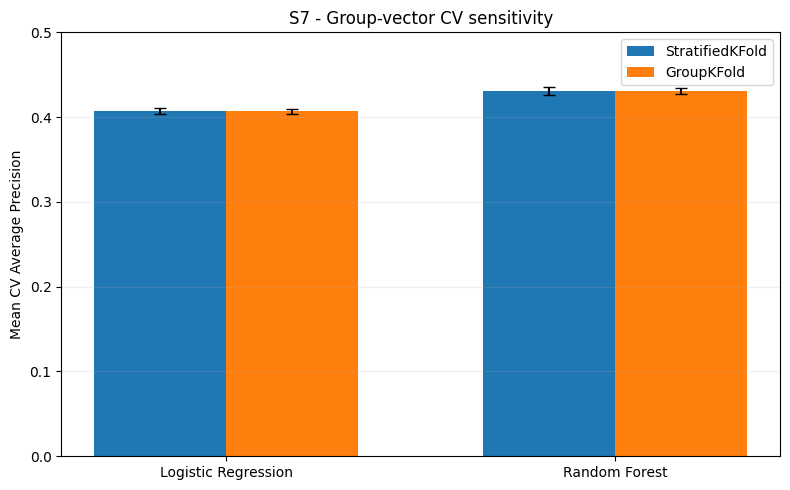

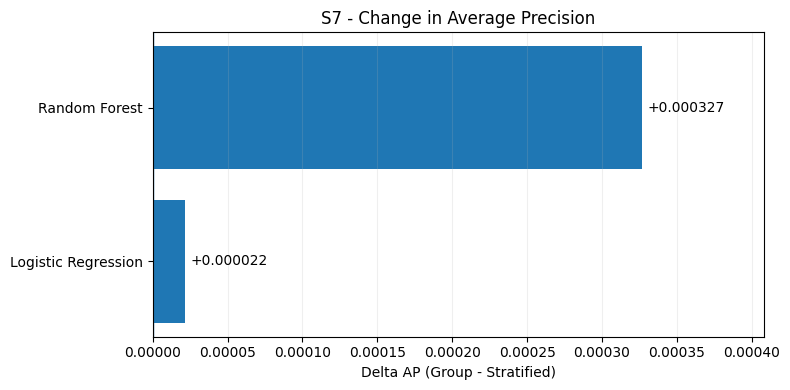

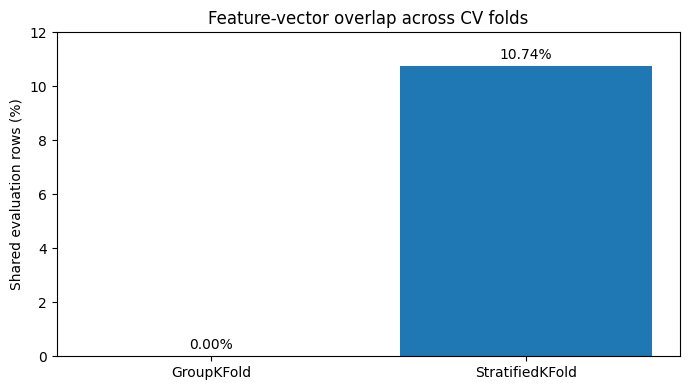


=== GENERATED FILES ===
s7_all_fold_results.csv | 1513 bytes
s7_all_cv_summary.csv | 571 bytes
s7_model_comparison.csv | 562 bytes
s7_overlap_summary.csv | 198 bytes
fig_S7_cv_ap.png | 92056 bytes
fig_S7_delta_ap.png | 81528 bytes
fig_S7_vector_overlap.png | 76963 bytes

S7.7: PASS


In [7]:

# ==========================================
# S7.7 - CONSOLIDATE RESULTS
# ==========================================

import matplotlib.pyplot as plt

# 1. Gộp kết quả từng fold
all_fold_results = pd.concat(
    [
        lr_fold_results,
        rf_fold_results
    ],
    ignore_index=True
)

assert len(all_fold_results) == 12

# 2. Gộp bảng summary
all_summary = pd.concat(
    [
        lr_summary,
        rf_summary
    ],
    ignore_index=True
)

assert len(all_summary) == 4

print("=== S7 FULL CV SUMMARY ===")

print(
    all_summary.round(6).to_string(index=False)
)


# 3. Tạo bảng so sánh
comparison_rows = []

historical_ap = {
    "B1_logistic": 0.4071,
    "B2_random_forest": 0.4304
}

for model_name in historical_ap:

    model_results = all_summary[
        all_summary["model"] == model_name
    ]

    stratified = model_results[
        model_results["method"]
        == "StratifiedKFold"
    ].iloc[0]

    group = model_results[
        model_results["method"]
        == "GroupKFold"
    ].iloc[0]

    ap_stratified = float(stratified["cv_AP"])
    ap_group = float(group["cv_AP"])

    comparison_rows.append({

        "model": model_name,

        "historical_cv_AP":
            historical_ap[model_name],

        "stratified_cv_AP":
            ap_stratified,

        "stratified_AP_std":
            stratified["cv_AP_std"],

        "group_cv_AP":
            ap_group,

        "group_AP_std":
            group["cv_AP_std"],

        "delta_AP_group_minus_stratified":
            ap_group - ap_stratified,

        "stratified_cv_AUC":
            stratified["cv_AUC"],

        "group_cv_AUC":
            group["cv_AUC"],

        "delta_AUC":
            group["cv_AUC"]
            - stratified["cv_AUC"],

        "historical_AP_match_4dp":
            round(ap_stratified, 4)
            == historical_ap[model_name]
    })

comparison = pd.DataFrame(comparison_rows)

print("\n=== S7 MODEL COMPARISON ===")

print(
    comparison.round(6).to_string(index=False)
)


# 4. Tổng hợp kết quả kiểm tra overlap
overlap_summary = (
    fold_audit.groupby("method")
    .agg(
        n_eval_total=("n_eval", "sum"),

        shared_eval_rows_total=(
            "shared_eval_rows", "sum"
        ),

        shared_groups_mean=(
            "shared_groups", "mean"
        ),

        index_overlap_total=(
            "index_overlap", "sum"
        )
    )
    .reset_index()
)

overlap_summary["shared_eval_rate"] = (
    overlap_summary["shared_eval_rows_total"]
    / overlap_summary["n_eval_total"]
)

print("\n=== VECTOR OVERLAP SUMMARY ===")

print(
    overlap_summary.round(6).to_string(
        index=False
    )
)


# 5. Lưu các bảng kết quả tổng hợp
all_fold_results.to_csv(
    OUT / "s7_all_fold_results.csv",
    index=False
)

all_summary.to_csv(
    OUT / "s7_all_cv_summary.csv",
    index=False
)

comparison.to_csv(
    OUT / "s7_model_comparison.csv",
    index=False
)

overlap_summary.to_csv(
    OUT / "s7_overlap_summary.csv",
    index=False
)


# 6. Biểu đồ CV-AP
labels = [
    "Logistic Regression",
    "Random Forest"
]

x = np.arange(len(labels))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    comparison["stratified_cv_AP"],
    width,
    yerr=comparison["stratified_AP_std"],
    capsize=4,
    label="StratifiedKFold"
)

ax.bar(
    x + width / 2,
    comparison["group_cv_AP"],
    width,
    yerr=comparison["group_AP_std"],
    capsize=4,
    label="GroupKFold"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Mean CV Average Precision")
ax.set_ylim(0, 0.5)

ax.set_title(
    "S7 - Group-vector CV sensitivity"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    OUT / "fig_S7_cv_ap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 7. Biểu đồ chênh lệch AP
deltas = comparison[
    "delta_AP_group_minus_stratified"
].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(labels, deltas)

ax.axvline(0, linewidth=1)
ax.set_xlabel("Delta AP (Group - Stratified)")
ax.set_title("S7 - Change in Average Precision")

ax.ticklabel_format(
    style="plain",
    axis="x",
    useOffset=False
)

ax.bar_label(
    bars,
    labels=[f"{d:+.6f}" for d in deltas],
    padding=4
)

ax.margins(x=0.25)
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

fig.savefig(
    OUT / "fig_S7_delta_ap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 8. Biểu đồ tỷ lệ vector chồng lấn
fig, ax = plt.subplots(figsize=(7, 4))

rates = (
    overlap_summary["shared_eval_rate"]
    .to_numpy() * 100
)

bars = ax.bar(
    overlap_summary["method"],
    rates
)

ax.set_ylabel("Shared evaluation rows (%)")
ax.set_ylim(0, 12)

ax.set_title(
    "Feature-vector overlap across CV folds"
)

ax.bar_label(
    bars,
    labels=[f"{r:.2f}%" for r in rates],
    padding=3
)

fig.tight_layout()

fig.savefig(
    OUT / "fig_S7_vector_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 9. Kiểm tra kết quả lịch sử
assert comparison[
    "historical_AP_match_4dp"
].all()

print("\n=== GENERATED FILES ===")

for name in [
    "s7_all_fold_results.csv",
    "s7_all_cv_summary.csv",
    "s7_model_comparison.csv",
    "s7_overlap_summary.csv",
    "fig_S7_cv_ap.png",
    "fig_S7_delta_ap.png",
    "fig_S7_vector_overlap.png"
]:
    path = OUT / name
    assert path.exists()
    print(path.name, "|", path.stat().st_size,
          "bytes")

print("\nS7.7: PASS")


In [8]:

# ==========================================
# S7.8A - QUALITY ASSURANCE
# ==========================================

import json
import platform
from datetime import datetime, timezone

qa_checks = {}

def mark_pass(name):
    qa_checks[name] = "PASS"
    print(f"[PASS] {name}")


# ------------------------------------------
# QA01: Dataset và train index
# ------------------------------------------

assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH
assert sha256_file(IDX_TRAIN_PATH) == EXPECTED_TRAIN_HASH

idx_disk = np.load(
    IDX_TRAIN_PATH,
    allow_pickle=False
)

assert np.array_equal(idx_disk, idx_train)

mark_pass("QA01_data_and_index_hash")


# ------------------------------------------
# QA02: Group ID
# ------------------------------------------

groups_disk = np.load(
    OUT / "group_ids_train.npy",
    allow_pickle=False
)

assert np.array_equal(groups_disk, groups)
assert len(groups_disk) == 177576
assert len(np.unique(groups_disk)) == 162300

assert len(X_train.drop_duplicates()) == 162300

mark_pass("QA02_group_ids")


# ------------------------------------------
# QA03 + QA04: Kiểm tra fold từ NPZ
# ------------------------------------------

methods = [
    "StratifiedKFold",
    "GroupKFold"
]

n = len(y_train)

splits_disk = {}
overlap_counts = {}

with np.load(
    OUT / "s7_cv_splits.npz",
    allow_pickle=False
) as split_file:

    for method in methods:

        splits_disk[method] = []
        all_eval = []
        total_shared_rows = 0

        for fold in range(1, 4):

            prefix = f"{method}_fold{fold}"

            tr = split_file[f"{prefix}_train"]
            ev = split_file[f"{prefix}_eval"]

            assert len(tr) == 118384
            assert len(ev) == 59192

            # Kiểm tra đầy đủ, không trùng index
            assert np.array_equal(
                np.sort(np.concatenate([tr, ev])),
                np.arange(n)
            )

            assert y_train.iloc[tr].nunique() == 2
            assert y_train.iloc[ev].nunique() == 2

            shared = np.intersect1d(
                groups_disk[tr],
                groups_disk[ev]
            )

            shared_rows = int(
                np.isin(
                    groups_disk[ev],
                    shared
                ).sum()
            )

            if method == "GroupKFold":
                assert len(shared) == 0
                assert shared_rows == 0

            total_shared_rows += shared_rows

            splits_disk[method].append((tr, ev))
            all_eval.append(ev)

        assert np.array_equal(
            np.sort(np.concatenate(all_eval)),
            np.arange(n)
        )

        overlap_counts[method] = total_shared_rows

assert overlap_counts["StratifiedKFold"] == 19078
assert overlap_counts["GroupKFold"] == 0

mark_pass("QA03_fold_integrity")
mark_pass("QA04_group_overlap")


# ------------------------------------------
# QA05 - QA08: Tính lại metrics từ OOF
# ------------------------------------------

model_files = {
    "B1_logistic": "s7_lr_oof_predictions.npz",
    "B2_random_forest": "s7_rf_oof_predictions.npz"
}

fold_csv = pd.read_csv(
    OUT / "s7_all_fold_results.csv"
)

assert len(fold_csv) == 12

recomputed_rows = []

ap_matches = 0
auc_matches = 0

for model_name, filename in model_files.items():

    with np.load(
        OUT / filename,
        allow_pickle=False
    ) as pred:

        # Kiểm tra căn chỉnh bản ghi
        assert np.array_equal(
            pred["row_indices"],
            idx_train
        )

        assert np.array_equal(
            pred["y_true"],
            y_train.to_numpy()
        )

        score_keys = {
            "StratifiedKFold": "scores_stratified",
            "GroupKFold": "scores_group"
        }

        for method, score_key in score_keys.items():

            scores = pred[score_key]

            assert scores.shape == (n,)
            assert np.isfinite(scores).all()
            assert ((scores >= 0) &
                    (scores <= 1)).all()

            for fold, (_, ev) in enumerate(
                splits_disk[method],
                start=1
            ):

                y_ev = pred["y_true"][ev]
                p_ev = scores[ev]

                # Tính lại AP và ROC-AUC
                ap = average_precision_score(
                    y_ev, p_ev
                )

                auc = roc_auc_score(
                    y_ev, p_ev
                )

                # Lấy kết quả CSV tương ứng
                ref = fold_csv[
                    (fold_csv["model"] == model_name)
                    & (fold_csv["method"] == method)
                    & (fold_csv["fold"] == fold)
                ]

                assert len(ref) == 1
                ref = ref.iloc[0]

                ap_match = np.isclose(
                    ap,
                    ref["AP"],
                    rtol=0,
                    atol=1e-12
                )

                auc_match = np.isclose(
                    auc,
                    ref["ROC_AUC"],
                    rtol=0,
                    atol=1e-12
                )

                assert ap_match
                assert auc_match

                ap_matches += int(ap_match)
                auc_matches += int(auc_match)

                recomputed_rows.append({
                    "model": model_name,
                    "method": method,
                    "fold": fold,
                    "AP_recomputed": ap,
                    "AP_csv": ref["AP"],
                    "AUC_recomputed": auc,
                    "AUC_csv": ref["ROC_AUC"],
                    "AP_match": bool(ap_match),
                    "AUC_match": bool(auc_match)
                })

assert ap_matches == 12
assert auc_matches == 12

mark_pass("QA05_oof_alignment")
mark_pass("QA06_score_range")
mark_pass("QA07_ap_12_of_12")
mark_pass("QA08_auc_12_of_12")


# ------------------------------------------
# QA09: Kiểm tra CV summary
# ------------------------------------------

qa_metrics = pd.DataFrame(recomputed_rows)

summary_disk = pd.read_csv(
    OUT / "s7_all_cv_summary.csv"
)

assert len(summary_disk) == 4

for (model_name, method), part in qa_metrics.groupby(
    ["model", "method"]
):

    ref = summary_disk[
        (summary_disk["model"] == model_name)
        & (summary_disk["method"] == method)
    ]

    assert len(ref) == 1
    ref = ref.iloc[0]

    calculated = {
        "cv_AP": part["AP_recomputed"].mean(),

        "cv_AP_std": np.std(
            part["AP_recomputed"], ddof=0
        ),

        "cv_AUC": part["AUC_recomputed"].mean(),

        "cv_AUC_std": np.std(
            part["AUC_recomputed"], ddof=0
        )
    }

    for metric, value in calculated.items():

        assert np.isclose(
            value,
            ref[metric],
            rtol=0,
            atol=1e-12
        )

mark_pass("QA09_cv_summary")


# ------------------------------------------
# QA10: Đối chiếu CV-AP lịch sử
# ------------------------------------------

historical = {
    "B1_logistic": 0.4071,
    "B2_random_forest": 0.4304
}

for model_name, expected in historical.items():

    row = summary_disk[
        (summary_disk["model"] == model_name)
        & (summary_disk["method"]
           == "StratifiedKFold")
    ]

    assert len(row) == 1

    observed = float(row["cv_AP"].iloc[0])

    assert round(observed, 4) == expected

mark_pass("QA10_historical_reproduction")


# ------------------------------------------
# QA11: Kiểm tra đầy đủ sản phẩm
# ------------------------------------------

expected_files = [
    "group_ids_train.npy",
    "s7_fold_audit.csv",
    "s7_cv_splits.npz",

    "s7_lr_fold_results.csv",
    "s7_lr_summary.csv",
    "s7_lr_oof_predictions.npz",

    "s7_rf_fold_results.csv",
    "s7_rf_summary.csv",
    "s7_rf_oof_predictions.npz",

    "s7_all_fold_results.csv",
    "s7_all_cv_summary.csv",
    "s7_model_comparison.csv",
    "s7_overlap_summary.csv",

    "fig_S7_cv_ap.png",
    "fig_S7_delta_ap.png",
    "fig_S7_vector_overlap.png"
]

for filename in expected_files:

    path = OUT / filename

    assert path.is_file()
    assert path.stat().st_size > 0

mark_pass("QA11_artifacts_16_of_16")


# ------------------------------------------
# Lưu kết quả QA
# ------------------------------------------

qa_metrics.to_csv(
    OUT / "s7_metrics_recomputed.csv",
    index=False
)

print("\n=== QA METRICS ===")

print(
    qa_metrics.round(6).to_string(index=False)
)

print("\n=== QA SUMMARY ===")
print("Checks passed:", len(qa_checks), "/ 11")
print("AP matches:", ap_matches, "/ 12")
print("ROC-AUC matches:", auc_matches, "/ 12")

print("\nS7.8A: PASS")


[PASS] QA01_data_and_index_hash
[PASS] QA02_group_ids
[PASS] QA03_fold_integrity
[PASS] QA04_group_overlap
[PASS] QA05_oof_alignment
[PASS] QA06_score_range
[PASS] QA07_ap_12_of_12
[PASS] QA08_auc_12_of_12
[PASS] QA09_cv_summary
[PASS] QA10_historical_reproduction
[PASS] QA11_artifacts_16_of_16

=== QA METRICS ===
           model          method  fold  AP_recomputed   AP_csv  AUC_recomputed  AUC_csv  AP_match  AUC_match
     B1_logistic StratifiedKFold     1       0.410416 0.410416        0.824698 0.824698      True       True
     B1_logistic StratifiedKFold     2       0.409120 0.409120        0.822806 0.822806      True       True
     B1_logistic StratifiedKFold     3       0.401669 0.401669        0.820061 0.820061      True       True
     B1_logistic      GroupKFold     1       0.410716 0.410716        0.824845 0.824845      True       True
     B1_logistic      GroupKFold     2       0.403330 0.403330        0.821432 0.821432      True       True
     B1_logistic      GroupKFo

In [9]:

# ==========================================
# S7.8B - PACKAGE QA EVIDENCE
# ==========================================

import zipfile
import matplotlib

assert len(qa_checks) == 11
assert all(v == "PASS" for v in qa_checks.values())


# 1. Lưu cấu hình thực nghiệm
run_config = {
    "task": "S7_group_vector_cv",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "scope": "train_only",

    "seed": SEED,
    "n_folds": N_FOLDS,

    "n_train": len(X_train),
    "n_features": X_train.shape[1],
    "n_groups": int(len(np.unique(groups))),

    "feature_names": X_train.columns.tolist(),

    "data_sha256": sha256_file(DATA_PATH),
    "train_index_sha256": sha256_file(
        IDX_TRAIN_PATH
    ),

    "primary_metric": "average_precision",

    "stratified_cv": {
        "n_splits": N_FOLDS,
        "shuffle": True,
        "random_state": SEED
    },

    "group_cv": {
        "n_splits": N_FOLDS,
        "group_definition":
            "identical feature vectors"
    },

    "logistic_regression": (
        lr_model.named_steps["clf"].get_params()
    ),

    "standard_scaler": (
        lr_model.named_steps["scaler"].get_params()
    ),

    "random_forest": rf_model.get_params(),

    "retuning": False,
    "resampling": False,
    "threshold_selection": False,

    "validation_used_for_cv": False,
    "holdout_test_used_for_cv": False,

    "group_id_method":
        "hash_pandas_object + factorize"
}

with open(
    OUT / "s7_run_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        run_config,
        f,
        indent=2,
        ensure_ascii=False
    )


# 2. Lưu môi trường thực nghiệm
environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "platform": platform.platform()
}

with open(
    OUT / "s7_environment.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(environment, f, indent=2)


# 3. Tạo báo cáo QA trước đóng gói
qa_report = {
    "task": "S7_group_vector_cv",

    "checks": qa_checks.copy(),

    "checks_passed_before_packaging": 11,

    "ap_matches": ap_matches,
    "ap_total": 12,

    "auc_matches": auc_matches,
    "auc_total": 12,

    "historical_AP_match_4dp": {
        "B1_logistic": True,
        "B2_random_forest": True
    },

    "overlap_counts": overlap_counts,

    "results": comparison.to_dict(
        orient="records"
    ),

    "scope": "train_only",

    "limitations": [
        "GroupKFold does not guarantee stratification.",
        "CV standard deviation is not a confidence interval.",
        "Results do not establish statistical equivalence.",
        "Holdout test independence is not established."
    ]
}

with open(
    OUT / "S7_QA_REPORT.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        qa_report,
        f,
        indent=2,
        ensure_ascii=False
    )


# 4. Tạo README
readme = """# S7 - Group-vector Cross-Validation

Scope: Train-only sensitivity analysis.

Models:
- B1 Logistic Regression
- B2 Random Forest

Methods:
- StratifiedKFold, 3 folds
- GroupKFold, 3 folds

Primary metric: Average Precision.

Main files:
- s7_model_comparison.csv
- s7_fold_audit.csv
- s7_metrics_recomputed.csv
- S7_QA_REPORT.json
- s7_run_config.json
- s7_environment.json
- sha256_manifest.json

The NPZ files contain out-of-fold predictions
on training records only.

These results are not holdout test results.

Notebook source must be preserved separately
for full experimental reproducibility.
"""

(OUT / "README_S7.md").write_text(
    readme,
    encoding="utf-8"
)


# 5. Danh sách sản phẩm bàn giao
package_files = expected_files + [
    "s7_metrics_recomputed.csv",
    "s7_run_config.json",
    "s7_environment.json",
    "S7_QA_REPORT.json",
    "README_S7.md"
]

assert len(package_files) == 21


# 6. Tạo SHA-256 manifest
manifest = {}

for filename in package_files:

    path = OUT / filename

    manifest[filename] = {
        "sha256": sha256_file(path),
        "bytes": path.stat().st_size
    }

with open(
    OUT / "sha256_manifest.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )

package_files.append(
    "sha256_manifest.json"
)


# 7. Tạo ZIP
ZIP_PATH = Path(
    "/kaggle/working/S7_QA_Evidence.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for filename in package_files:

        z.write(
            OUT / filename,
            arcname=f"S7/{filename}"
        )


# 8. QA12: Kiểm tra ZIP thực tế
with zipfile.ZipFile(
    ZIP_PATH,
    mode="r"
) as z:

    # Kiểm tra lỗi CRC
    assert z.testzip() is None

    expected_names = {
        f"S7/{filename}"
        for filename in package_files
    }

    assert set(z.namelist()) == expected_names
    assert len(z.namelist()) == 22

    # Kiểm tra SHA-256 mọi tệp trong ZIP
    for filename, info in manifest.items():

        data = z.read(f"S7/{filename}")

        actual_hash = hashlib.sha256(
            data
        ).hexdigest()

        assert actual_hash == info["sha256"]
        assert len(data) == info["bytes"]

    # Kiểm tra manifest trong ZIP
    archived_manifest = z.read(
        "S7/sha256_manifest.json"
    )

    assert archived_manifest == (
        OUT / "sha256_manifest.json"
    ).read_bytes()

mark_pass("QA12_zip_integrity")


# 9. Tổng kết
print("\n=== S7 FINAL QA SUMMARY ===")

for name, status in qa_checks.items():
    print(name, ":", status)

print("\nTotal checks:", len(qa_checks), "/ 12")
print("AP recalculation:", ap_matches, "/ 12")
print("AUC recalculation:", auc_matches, "/ 12")
print("Packaged files:", len(package_files))
print("Manifest hash matches:", len(manifest), "/ 21")

print("\nZIP:", ZIP_PATH)
print(
    "ZIP size (MB):",
    round(ZIP_PATH.stat().st_size / 1024**2, 2)
)

print("ZIP SHA-256:", sha256_file(ZIP_PATH))

print("\nS7.8: PASS")


[PASS] QA12_zip_integrity

=== S7 FINAL QA SUMMARY ===
QA01_data_and_index_hash : PASS
QA02_group_ids : PASS
QA03_fold_integrity : PASS
QA04_group_overlap : PASS
QA05_oof_alignment : PASS
QA06_score_range : PASS
QA07_ap_12_of_12 : PASS
QA08_auc_12_of_12 : PASS
QA09_cv_summary : PASS
QA10_historical_reproduction : PASS
QA11_artifacts_16_of_16 : PASS
QA12_zip_integrity : PASS

Total checks: 12 / 12
AP recalculation: 12 / 12
AUC recalculation: 12 / 12
Packaged files: 22
Manifest hash matches: 21 / 21

ZIP: /kaggle/working/S7_QA_Evidence.zip
ZIP size (MB): 7.51
ZIP SHA-256: 9a156de957b6dfb3391b3bc4ee0649fa4b50285dce93db65ab32b4fb79a64a11

S7.8: PASS
